## Python - Manejo de Errores: try/except y Excepciones

### 1. Introducción: ¿Qué pasa cuando algo sale mal?

Imaginá que estás escribiendo un programa y le pedís al usuario que ingrese un número.

En condiciones normales todo funciona, pero un usuario puede ingresar:

- un número válido;
- `0`;
- una palabra como `hola`.

En este bloque vamos a **provocar errores primero**, observar qué hace Python y después aprender a controlarlos con `try` y `except`.

> Antes de ejecutar cada ejemplo, intentá anticipar qué va a pasar.


## Captura de excepciones

### 🔎 Primer experimento

Las próximas tres celdas forman un único programa:

1. pedimos un valor;
2. calculamos `100 / numero`;
3. mostramos el resultado.

Probalo con:

- `5`
- `0`
- `hola`

Antes de cada prueba preguntate:

- ¿llega hasta el `print()`?
- ¿en qué línea falla?
- ¿qué error muestra Python?

Por ahora **no queremos solucionar nada**. Primero queremos entender qué pasa.


In [1]:
numero = int(input("Ingrese un número: "))

ValueError: invalid literal for int() with base 10: 'hola'

In [2]:
resultado = 100/numero

NameError: name 'numero' is not defined

In [3]:
print (f"100 dividido {numero} es : {resultado}")

NameError: name 'numero' is not defined

## 2. La Solución: `try` y `except`

Ya vimos que un error puede detener el programa.

`try/except` permite decirle a Python:

> “Intentá ejecutar este código. Si algo falla, no te detengas: hacé otra cosa.”

### 🧠 ¿Qué descubrimos en el ejemplo anterior?

- Con `5`, todo funciona.
- Con `0`, aparece `ZeroDivisionError`.
- Con `hola`, aparece `ValueError`.

El tipo de error depende de **qué operación falló**.


### 2.2 Sintaxis Básica

La estructura general es:

```python
try:
    # código que puede fallar
except:
    # qué hacer si ocurre un error
```

La idea importante es el **flujo**: Python intenta primero el bloque `try`.  
Solo entra al `except` si ocurre una excepción.


In [10]:
try:
  codigo_riesgoso()


except:
  print ("esto no está funcionando, hay algo mal")

esto no está funcionando, hay algo mal


### 2.3 Primer Ejemplo Práctico

Vamos a comparar dos funciones que intentan hacer exactamente lo mismo: dividir dos números.

La diferencia está en qué ocurre **cuando algo sale mal**.

#### `division_peligrosa()`
No controla errores.

#### `division_segura()`
Usa `try/except`.

### 🧪 Probá ambas con:

| Primer valor | Segundo valor | Qué estamos probando |
|---|---:|---|
| `10` | `5` | Caso normal |
| `10` | `0` | División por cero |
| `hola` | `5` | Texto donde esperamos un número |

Con `10 / 5`, probablemente no notes ninguna diferencia.  
La diferencia aparece en los casos problemáticos.


In [11]:
def division_peligrosa ():
  a = int(input("ingrese primer numero"))
  b= int (input("ingrese segundo numero"))
  resultado = a/b
  print (f"el resultado es {resultado}")


In [12]:
division_peligrosa ()

ingrese primer numero10
ingrese segundo numero5
el resultado es 2.0


In [13]:
def division_segura ():
  try:
    a = int(input("ingrese primer numero"))
    b= int (input("ingrese segundo numero"))
    resultado = a/b
    print (f"el resultado es {resultado}")

  except:
    print ("algo salió mal con los numeros ingresados")




In [14]:
division_segura ()

ingrese primer numero10
ingrese segundo numero10
el resultado es 1.0


### 2.4 Ejemplo Visual del Flujo

Ahora vamos a seguir el recorrido del programa.

Primero ejecutá el ejemplo tal como está.

Después cambiá:

```python
resultado = 10 / 10
```

por:

```python
resultado = 10 / 0
```

Antes de ejecutar, intentá anticipar qué mensajes se van a imprimir.

### 🧠 Idea a descubrir

Cuando una línea dentro del `try` falla:

1. Python deja de ejecutar el resto del `try`;
2. salta al `except`;
3. después continúa con lo que esté fuera de ambos bloques.


In [15]:
def ejemplo_flujo():
  print("1.este es el primer mensaje")

  try:
    print("2.intentando la operacion...")
    resultado = 10 / 10  # Simulando una división por cero
    print("3. esta linea se ejecuta o no????")

  except:
    print("4.capturamos el error")

  print("5.paso 5")

In [16]:
ejemplo_flujo()

1.este es el primer mensaje
2.intentando la operacion...
3. esta linea se ejecuta o no????
5.paso 5


## 3. Tipos de Excepciones y Manejo Específico
### 3.1 ¿Por qué existen diferentes tipos de excepciones?

#### Python tiene diferentes tipos de excepciones porque cada error tiene una causa diferente y requiere una solución diferente:



*   ValueError: El tipo está bien, pero el valor es incorrecto → "No puedo convertir 'abc' a número"
*   ZeroDivisionError: Problema matemático → "No se puede dividir por cero"
*   IndexError: Problema con listas → "Ese índice no existe"
*   KeyError: Problema con diccionarios → "Esa clave no existe"








### 3.2 `except` genérico: detectar que algo salió mal

Hasta ahora usamos un `except` genérico.

Eso significa que Python entra al `except` frente a distintos tipos de error, pero el mensaje que mostramos es siempre el mismo.

Primero vamos a probar **un solo error por vez**.


#### Prueba 1 · División por cero

Antes de ejecutar, pensá:

> ¿Qué debería pasar cuando Python intenta calcular `10 / 0`?


In [17]:
def ejemplo_generico_division():
    try:
        resultado = 10 / 0
    except:
        print("Hay algo que salió mal")

ejemplo_generico_division()


Hay algo que salió mal


### ¿Qué ocurrió?

Python intentó hacer la división y se produjo un error.

Como la operación estaba dentro de `try`, el programa pasó al bloque `except` y mostró el mensaje.

Todavía no distinguimos **qué tipo de error** ocurrió.


#### Prueba 2 · Posición inexistente en una lista

Una lista con tres elementos tiene posiciones `0`, `1` y `2`.

Ahora vamos a intentar acceder a la posición `10`.

Antes de ejecutar, anticipá qué pasará.


In [18]:
def ejemplo_generico_lista():
    try:
        lista = [1, 2, 3]
        elemento = lista[10]
    except:
        print("Hay algo que salió mal")

ejemplo_generico_lista()


Hay algo que salió mal


### ¿Qué ocurrió?

El error fue distinto al anterior, pero el `except` genérico volvió a mostrar exactamente el mismo mensaje.

Eso nos permite manejar el problema, pero no identificar cuál fue.


#### Prueba 3 · Conversión incorrecta

Ahora intentamos convertir el texto `"cuarenta"` a número entero.

Antes de ejecutar, pensá si esa conversión es posible.


In [19]:
def ejemplo_generico_conversion():
    try:
        edad = int("cuarenta")
    except:
        print("Hay algo que salió mal")

ejemplo_generico_conversion()


Hay algo que salió mal


### Conclusión

Probamos tres errores diferentes:

- división por cero;
- índice inexistente;
- conversión incorrecta.

En los tres casos el `except` genérico respondió igual.

Por eso ahora vamos a aprender a capturar **errores específicos**.


### 3.3 Excepciones específicas

Python tiene distintos tipos de excepciones.

Algunas que vamos a usar:

- `ZeroDivisionError` → división por cero;
- `IndexError` → posición inexistente en una lista;
- `ValueError` → conversión o valor inválido.

Vamos a probarlas de a una.


In [20]:
try:
    resultado = 10 / 0
except ZeroDivisionError:
    print("No se puede dividir por cero")


No se puede dividir por cero


In [21]:
try:
    lista = [1, 2, 3]
    elemento = lista[10]
except IndexError:
    print("La posición solicitada no existe")


La posición solicitada no existe


In [22]:
try:
    edad = int("cuarenta")
except ValueError:
    print("El valor ingresado no puede convertirse a entero")


El valor ingresado no puede convertirse a entero


### ¿Qué ganamos al ser específicos?

Ahora el programa puede mostrar un mensaje diferente según el problema.

Eso hace que el código sea más claro y que el usuario reciba información útil sobre lo que ocurrió.


In [23]:
def mostrar_diferencias():
    datos = {"nombre": "Ana", "edad": 25}
    numeros = [10, 20, 30]

    print("Probando diferentes errores...")

    try:
        apellido = datos["apellido"]  # Esta clave no existe
    except KeyError:
        print("🔑 KeyError: La clave 'apellido' no existe en el diccionario")

    try:
        numero = numeros[5]  # Este índice no existe
    except IndexError:
        print("📋 IndexError: El índice 5 no existe en la lista")

    try:
        edad_convertida = int("treinta")  # No se puede convertir
    except ValueError:
        print("🔢 ValueError: No se puede convertir 'treinta' a número")

    try:
        division = 100 / 0  # División por cero
    except ZeroDivisionError:
        print("➗ ZeroDivisionError: No se puede dividir por cero")

mostrar_diferencias()

Probando diferentes errores...
🔑 KeyError: La clave 'apellido' no existe en el diccionario
📋 IndexError: El índice 5 no existe en la lista
🔢 ValueError: No se puede convertir 'treinta' a número
➗ ZeroDivisionError: No se puede dividir por cero


### ✅ Resumen

`try/except` te permite:

- 🛡️ proteger el programa frente a errores;
- 🔄 continuar ejecutando cuando sea posible;
- 👥 dar mensajes más comprensibles al usuario;
- 🎯 reaccionar de forma distinta según el tipo de excepción.

Antes de avanzar, intentá responder sin mirar:

1. ¿qué diferencia hay entre `try` y `except`?
2. ¿qué error aparece al dividir por cero?
3. ¿qué ventaja tiene capturar una excepción específica?


## Python - Bucles y List Comprehension

Los bucles permiten repetir instrucciones de forma automática.

En este bloque vas a trabajar con:

- `for`
- `while`
- list comprehension
- `break`
- `continue`

La pregunta que nos va a acompañar es:

> **¿Qué parte del proceso se repite y qué parte cambia en cada vuelta?**


## 1. Introducción: ¿Por qué necesitamos bucles?

Imaginá que querés imprimir los números del 1 al 100.

Podrías escribir:

```python
print(1)
print(2)
print(3)
...
```

pero sería repetitivo, difícil de mantener y poco práctico.

Los bucles nos permiten expresar esa repetición de forma mucho más compacta.

Antes de ejecutar el `for` con `range(1, 101)`, preguntate:

- ¿incluye el `1`?
- ¿incluye el `101`?
- ¿cuántas vueltas hará?


In [24]:
print (1)
print (2)
print (3)

1
2
3


Los bucles nos permiten repetir código de manera eficiente:

In [25]:
range (1, 101)

range(1, 101)

In [26]:
for x in range (1, 101) :
  print(x)



1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100


In [30]:
for numero in range(5, 0, -1):
    print(numero)

5
4
3
2
1


## 2. Bucle FOR - "Para cada elemento..."

### 2.1 Concepto

El bucle `for` se usa cuando queremos recorrer una colección o repetir una acción una cantidad conocida de veces.

Pensalo así:

> “Para cada elemento de esta secuencia, hacé algo.”

Ejemplos de secuencias:

- listas;
- textos;
- rangos de números;
- otras colecciones.


2.2 Sintaxis Básica

### 2.3 Ejemplos Prácticos

Ejecutá los ejemplos siguientes uno por uno.

Antes de hacerlo, intentá predecir:

- qué valor toma la variable del `for` en cada vuelta;
- cuántas veces se ejecuta el bloque;
- cuál será el último valor procesado.


#### Paso 1 · Recorrer una lista

Primero miramos un `for` sencillo.

La variable `nombre` va tomando un valor distinto en cada vuelta.


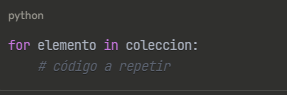

In [31]:
nombres = ["Ana", "Carlos", "María"]

for nombre in nombres:
    print(f"Hola, {nombre}")


Hola, Ana
Hola, Carlos
Hola, María


In [32]:
nombres = ["Ana", "Carlos", "María"]

for posicion, nombre in enumerate(nombres):
    print(posicion, nombre)


0 Ana
1 Carlos
2 María


In [33]:
for numero in range(0, 11, 2):
    print(numero)


0
2
4
6
8
10


In [34]:
# 🧪 Probá cambiar uno de los tres argumentos de range()
for numero in range(1, 6):
    print(numero)

# Pregunta:


1
2
3
4
5


## 3. Bucle WHILE - "Mientras que..."

### 3.1 Concepto

`while` se usa cuando no sabemos necesariamente cuántas veces vamos a repetir algo.

El ciclo continúa **mientras una condición sea verdadera**.

La pregunta más importante al usar `while` es:

> **¿Qué hará que la condición deje de cumplirse?**

Si la respuesta es “nada”, podemos crear un bucle infinito.


Antes de ejecutar cada `while`, identificá:

1. la condición;
2. la variable que cambia;
3. qué hace que el ciclo termine.

Si nada modifica la condición, el ciclo puede no terminar.


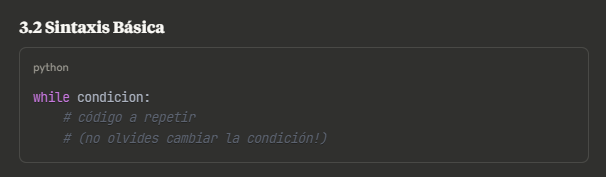

### 3.3 Ejemplos Prácticos

En los siguientes ejemplos buscá identificar siempre:

1. cuál es la condición del `while`;
2. qué variable cambia;
3. qué provoca que el ciclo termine.

No te limites a mirar el resultado: seguí el flujo vuelta por vuelta.


In [35]:

contador = 1
print("Contando con while:")
while contador <= 5:
    print(f"Contador: {contador}")
    contador += 1  # ¡Importante! Cambiar la condición

print("\n" + "="*30 + "\n")



Contando con while:
Contador: 1
Contador: 2
Contador: 3
Contador: 4
Contador: 5




In [36]:
numero_secreto = 7
intentos = 0

print("Adivina el número (entre 1 y 10):")
while True:
    try:
        guess = int(input("Tu número: "))
        intentos += 1

        if guess == numero_secreto:
            print(f"¡Correcto! Lo lograste en {intentos} intentos")
            break
        elif guess < numero_secreto:
            print("Muy bajo, intenta de nuevo")
        else:
            print("Muy alto, intenta de nuevo")

    except ValueError:
        print("Por favor ingresa un número válido")
    except KeyboardInterrupt:
        print("\n¡Hasta luego!")
        break




print("\n" + "="*30 + "\n")





Adivina el número (entre 1 y 10):
Tu número: 1
Muy bajo, intenta de nuevo
Tu número: 8
Muy alto, intenta de nuevo
Tu número: 9
Muy alto, intenta de nuevo
Tu número: 4
Muy bajo, intenta de nuevo
Tu número: 5
Muy bajo, intenta de nuevo
Tu número: 6
Muy bajo, intenta de nuevo
Tu número: 7
¡Correcto! Lo lograste en 7 intentos




In [37]:
nombres = ["Ana", "Carlos", "Pedro", "María", "Luis"]
buscar = "Pedro"
encontrado = False
indice = 0

print(f"Buscando '{buscar}' en la lista...")
while indice < len(nombres) and not encontrado:
    if nombres[indice] == buscar:
        print(f"¡Encontrado! {buscar} está en la posición {indice}")
        encontrado = True
    else:
        indice += 1

if not encontrado:
    print(f"{buscar} no está en la lista")

Buscando 'Pedro' en la lista...
¡Encontrado! Pedro está en la posición 2


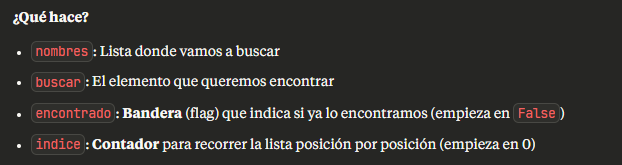

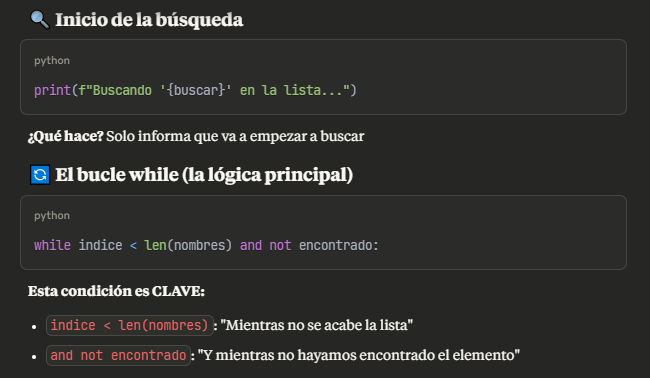

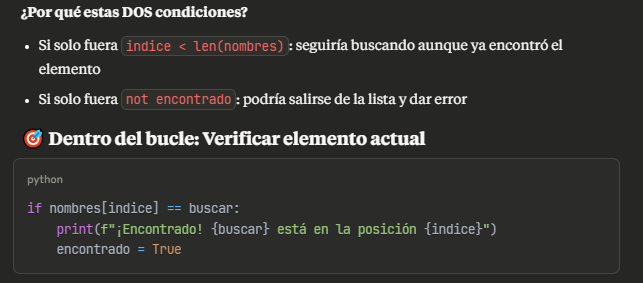

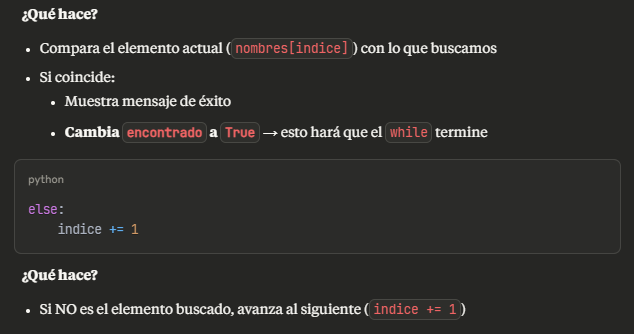

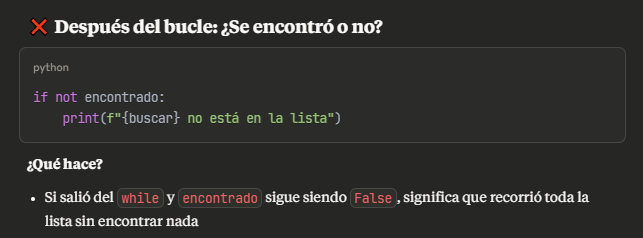

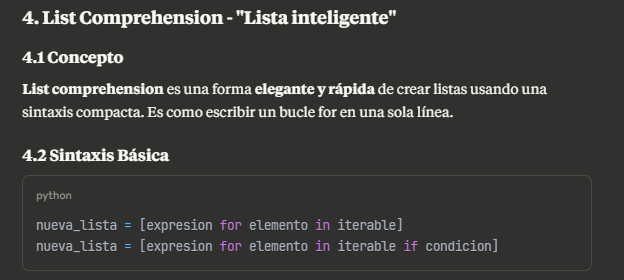

### 4.3 Comparación: FOR tradicional vs List Comprehension

Las próximas celdas resuelven el mismo problema de dos maneras:

- con un `for` tradicional;
- con list comprehension.

Antes de ejecutar, intentá anticipar qué contendrán:

```python
cuadrados_for
```

y

```python
cuadrados_lc
```

Después compará cuál te resulta más fácil de leer.


In [38]:
numeros = [1, 2, 3, 4, 5]

In [39]:
cuadrados_for = []
for num in numeros:
    cuadrados_for.append(num ** 2)

In [40]:
cuadrados_lc = [num ** 2 for num in numeros ]

In [41]:
print("Números originales:", numeros)
print("Cuadrados (for):", cuadrados_for)
print("Cuadrados (list comp):", cuadrados_lc)

print("\n" + "="*40 + "\n")

Números originales: [1, 2, 3, 4, 5]
Cuadrados (for): [1, 4, 9, 16, 25]
Cuadrados (list comp): [1, 4, 9, 16, 25]




### 🧠 ¿Qué pasó?

Las dos formas producen el mismo resultado.

Con `for`:

1. creamos una lista vacía;
2. recorremos cada número;
3. calculamos el cuadrado;
4. usamos `append()`.

Con list comprehension:

```python
[num ** 2 for num in numeros]
```

expresamos todo en una sola construcción.

No siempre “más corto” significa “mejor”.  
Conviene usar list comprehension cuando la transformación sigue siendo clara.


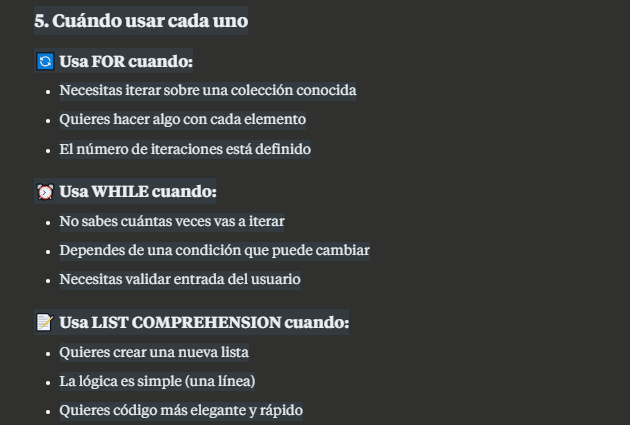

## BREAK: Salir de bucles

`break` termina **completamente** el bucle actual.

Es útil cuando ya encontramos lo que buscábamos y no tiene sentido seguir recorriendo.

Antes de ejecutar los ejemplos, intentá anticipar:

> ¿en qué valor se detendrá el ciclo?


Vamos a ver `break` en dos pasos:

1. primero en un ejemplo simple;
2. después aplicado a una búsqueda.

No modifiques nada hasta haber ejecutado ambos.


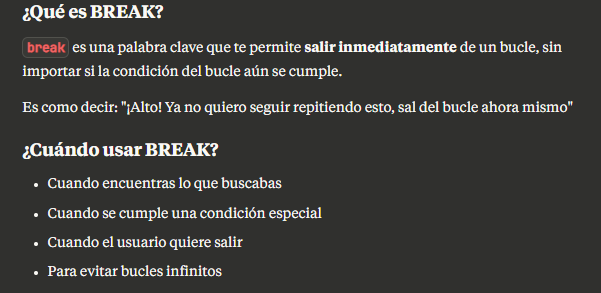

In [42]:
for i in range(10):
    print("i =", i)
    if i == 3:
        print("Se cumple la condición → salimos del bucle")
        break


i = 0
i = 1
i = 2
i = 3
Se cumple la condición → salimos del bucle


In [43]:
productos = ["mouse", "teclado", "monitor", "auriculares"]
buscar = "monitor"

for producto in productos:
    print("Revisando:", producto)
    if producto == buscar:
        print("Encontrado:", producto)
        break


Revisando: mouse
Revisando: teclado
Revisando: monitor
Encontrado: monitor


In [44]:
# 🧪 TU TURNO
# Modificá 'limite' y observá dónde se detiene.
limite = 5

for i in range(10):
    print(i)
    if i == limite:
        break


0
1
2
3
4
5


### 🧠 ¿Qué hace `break`?

En cada vuelta del `for`, Python procesa un elemento.

Cuando se cumple la condición del `if`, se ejecuta `break` y el ciclo termina inmediatamente.

Los elementos que quedaban después **ya no se procesan**.

Idea clave:

> `break` = “ya terminé de buscar / ya se cumplió lo que necesitaba”.


## CONTINUE: Saltar a la siguiente iteración

`continue` no termina el bucle.

Solo salta el resto de las instrucciones de **esa vuelta** y continúa con la siguiente.

Antes de ejecutar el ejemplo, intentá predecir qué valor no se imprimirá.


Con `continue`, el bucle no termina.

Solo se omite el resto de la vuelta actual y se pasa a la siguiente.


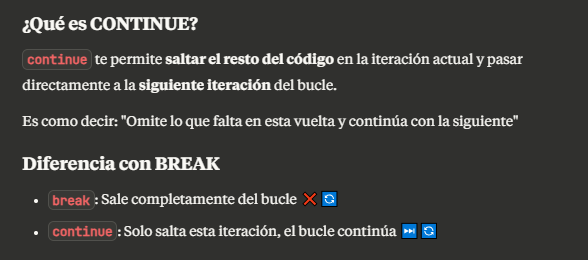

In [45]:
for i in range(6):
    if i == 2:
        print("Saltamos el 2")
        continue

    print(i)


0
1
Saltamos el 2
3
4
5


### 🧠 Diferencia fundamental

- `break` → termina el bucle completo.
- `continue` → salta una iteración y sigue.

En el ejemplo, cuando `i == 2`, Python ejecuta `continue` y vuelve al inicio del `for`.

Por eso el `2` no llega al `print(i)`, pero `3`, `4` y `5` sí se procesan.


## Interpretación código (Alumnos)

No ejecutes todavía la próxima celda.

Seguí el valor de `i` manualmente y anotá:

- valor inicial;
- valor después de `i += 1`;
- qué se imprime;
- cuándo se cumple el `if`;
- por qué termina el `while`.

Después ejecutá y compará.


In [46]:
i = 1
while i > 0:
    i += 1
    print(i)
    if i == 10:
        break #explique cada paso que se realiza en el proceso de iteración

2
3
4
5
6
7
8
9
10


## Importar Librerías y Módulos

Python permite reutilizar funciones que ya existen en otros módulos o librerías.

En esta sección solo necesitamos entender **las formas principales de importar**.

### Dos ideas previas

- **Biblioteca estándar:** viene incluida con Python, por ejemplo `math`, `random` o `datetime`.
- **Librería externa:** puede requerir instalación, como `pandas` o `matplotlib`.

Más adelante veremos cómo instalar las librerías externas.


## 1. Importar un módulo completo

La forma más directa es:

```python
import math
```

Después usamos el nombre del módulo para acceder a sus funciones:

```python
math.sqrt(25)
```


In [47]:
import math

print(math.sqrt(25))
print(math.pi)


5.0
3.141592653589793


## 2. Importar una función específica

Si solamente necesitamos una función, podemos escribir:

```python
from math import sqrt
```

En ese caso ya no escribimos `math.sqrt()`, sino directamente `sqrt()`.

Las dos formas son válidas. Cambia cómo accedemos a la función.


In [48]:
from math import sqrt

print(sqrt(81))


9.0


## 3. Importar usando un alias

`as` permite darle un nombre más corto al módulo.

Ejemplo:

```python
import datetime as dt
```

`dt` no es una librería nueva: es simplemente otro nombre para `datetime`.


In [49]:
import datetime as dt

hoy = dt.date.today()
print(hoy)


2026-09-14


## 4. `from ... import *`

También existe:

```python
from math import *
```

Esto importa muchos nombres de una sola vez.

Funciona, pero **no es recomendable** porque después puede resultar difícil saber de qué módulo proviene cada función.

Para empezar, es preferible usar:

```python
import modulo
```

o:

```python
from modulo import funcion
```


## Resumen de las formas de importar

| Forma | Ejemplo | Cómo se usa después |
|---|---|---|
| Módulo completo | `import math` | `math.sqrt(25)` |
| Función específica | `from math import sqrt` | `sqrt(25)` |
| Con alias | `import datetime as dt` | `dt.date.today()` |
| Importar todo | `from math import *` | No recomendado |

No hace falta memorizar todas las variantes. Lo importante es reconocer qué significa cada una cuando aparezca en un código.


## Un ejemplo con otro módulo estándar

`random` también viene incluido con Python, por lo que no necesita instalación.

La siguiente función genera un número entero aleatorio.


In [50]:
import random

numero = random.randint(1, 10)
print("Número aleatorio:", numero)


Número aleatorio: 2


## Mini ejercicio

Usá `datetime` para obtener la fecha de hoy.

Completá solamente el nombre que falta.


In [52]:
import datetime as dt

hoy = dt.date.today()
print(hoy)

2026-09-14


### ✅ Conclusión

Para esta clase alcanza con recordar:

- `import modulo`
- `from modulo import funcion`
- `import modulo as alias`

Y reconocer que `from modulo import *` existe, aunque normalmente conviene evitarlo.

Con esto ya tenemos lo necesario para avanzar a **Pandas**.


## Instalación

A partir de acá empezamos a trabajar con una librería externa: **Pandas**.

Una librería externa puede necesitar instalación antes de usarse.

En Google Colab podemos instalar paquetes con:

```python
!pip install nombre_paquete
```

### ¿Qué significa?

- `pip` → gestor de paquetes de Python;
- `install` → instala el paquete;
- `!` → indica a Colab que ejecute el comando en el sistema.

También instalamos `matplotlib`, que usaremos más adelante para gráficos.

> Colab suele traer ambas librerías instaladas, pero ejecutamos esta celda para asegurar que el entorno tenga todo lo necesario.


In [53]:
!pip install -q pandas matplotlib  # (-q significa quiet y reduce los mensajes que muestra pip durante la instalación. No cambia qué se instala.)

import pandas as pd
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("Entorno listo ✅")


Pandas: 2.2.3
Entorno listo ✅


## 2. Conceptos Fundamentales

Ahora que Pandas está disponible, vamos a conocer sus dos estructuras principales:

- `Series`
- `DataFrame`

Primero trabajaremos con ejemplos pequeños y después cargaremos un archivo real.


### 2.1 Series - Una columna de datos

Una `Series` puede pensarse como una columna de valores con un índice asociado.

Ejecutá los ejemplos y observá:

- los valores;
- el índice;
- qué diferencia hay respecto de una lista común de Python.


In [54]:
ventas = pd.Series([120, 150, 90, 180])
print(ventas)


0    120
1    150
2     90
3    180
dtype: int64


In [55]:
ventas = pd.Series(
    [120, 150, 90],
    index=["Lunes", "Martes", "Miércoles"]
)

print(ventas)
print("\nVentas del martes:", ventas["Martes"])


Lunes        120
Martes       150
Miércoles     90
dtype: int64

Ventas del martes: 150



### Cuándo Usar Series:
* Análisis de Datos: Utiliza Series cuando trabajas con datos que requieren análisis y manipulación. Las Series son ideales para realizar operaciones estadísticas, agregaciones, y filtrado en grandes conjuntos de datos.
* Datos Etiquetados: Cuando tus datos tienen etiquetas asociadas (índices) y quieres aprovechar el etiquetado para acceder a elementos de manera más intuitiva.
* Operaciones Vectorizadas: Si necesitas realizar operaciones matemáticas o estadísticas en todos los elementos de la Series de manera eficiente y vectorizada.

####Ventajas:
* Etiquetas (Índices): Puedes asignar etiquetas a los elementos, lo que facilita el acceso y la manipulación de datos.
* Operaciones Vectorizadas: Las operaciones en Series son vectorizadas y se realizan de manera eficiente en grandes conjuntos de datos.
* Integración con DataFrames: Series es la base para las columnas en un DataFrame de pandas.

###Listas de Python
####Cuándo Usar Listas:
* Estructura de Datos General: Utiliza listas para almacenar secuencias de elementos cuando no necesitas las funcionalidades avanzadas de pandas. Las listas son adecuadas para almacenamiento y manipulación básicos.
* Flexibilidad: Cuando necesitas una estructura de datos sencilla y flexible sin requerir etiquetas o operaciones vectorizadas.
* Tipos de Datos Mixtos: Las listas permiten almacenar elementos de diferentes tipos de datos.

####Ventajas:
* Simplicidad: Son una estructura de datos simple y flexible, ideal para tareas básicas y cuando no se requiere funcionalidad avanzada.
Tipos de Datos Mixtos: Puedes mezclar diferentes tipos de datos en una sola lista.

En resumen, usa Series de pandas cuando necesites análisis avanzado de datos, etiquetado, o eficiencia en operaciones matemáticas. Usa listas de Python para almacenamiento general y manipulación básica cuando no necesites las características avanzadas de pandas.

## 2.2 DataFrame - Una tabla completa

Un `DataFrame` organiza datos en filas y columnas.

Pensalo como una tabla en la que:

- cada columna representa una variable;
- cada fila representa una observación.

Primero vamos a crear uno manualmente para entender su estructura.


In [56]:
datos = {
    "producto": ["A", "B", "C", "A", "B"],
    "ventas": [120, 150, 90, 180, 130],
    "region": ["Norte", "Sur", "Norte", "Sur", "Norte"]
}

df_ejemplo = pd.DataFrame(datos)
df_ejemplo


,producto,ventas,region
0,A,120,Norte
1,B,150,Sur
2,C,90,Norte
3,A,180,Sur
4,B,130,Norte


## 3. Explorando los Datos - Primeros Pasos

### 3.1 Información básica del DataFrame

Antes de analizar una tabla conviene conocer:

- dimensiones;
- nombres de columnas;
- tipos de datos;
- primeras filas.

No conviene empezar a calcular sin saber qué tenemos.


In [57]:
print("Dimensiones:", df_ejemplo.shape)
print("\nColumnas:", df_ejemplo.columns.tolist())
print("\nTipos:")
print(df_ejemplo.dtypes)

display(df_ejemplo.head())


Dimensiones: (5, 3)

Columnas: ['producto', 'ventas', 'region']

Tipos:
producto    object
ventas       int64
region      object
dtype: object


,producto,ventas,region
0,A,120,Norte
1,B,150,Sur
2,C,90,Norte
3,A,180,Sur
4,B,130,Norte


## 3.2 Acceder a los datos

Podemos seleccionar:

- una columna;
- varias columnas;
- una fila por posición;
- filas que cumplan una condición.

Ejecutá el ejemplo y observá cómo cambia el resultado.


In [58]:
print("Columna ventas:")
print(df_ejemplo["ventas"])

print("\nPrimera fila:")
print(df_ejemplo.iloc[0])

print("\nFilas del producto A:")
display(df_ejemplo.loc[df_ejemplo["producto"] == "A"])


Columna ventas:
0    120
1    150
2     90
3    180
4    130
Name: ventas, dtype: int64

Primera fila:
producto        A
ventas        120
region      Norte
Name: 0, dtype: object

Filas del producto A:


,producto,ventas,region
0,A,120,Norte
3,A,180,Sur


## 4. Cargar Datos Reales

### 4.1 Subir `ventas.csv` a Google Colab

Ahora sí vamos a trabajar con el archivo real **`ventas.csv`** que acompaña esta actividad.

### Opción A · Desde el panel izquierdo de Colab

1. Abrí el ícono de **carpeta 📁**.
2. Hacé clic en **Subir archivo**.
3. Seleccioná `ventas.csv`.
4. Esperá hasta que aparezca en la lista.

### Opción B · Desde Python

La próxima celda abre un selector para elegir el archivo desde tu computadora.

> Si ya lo subiste desde el panel izquierdo, no necesitás volver a cargarlo.


Hasta acá trabajamos con datos pequeños creados dentro del notebook.

Ahora pasamos a un archivo real.

Primero lo subimos a Colab.  
Después lo leemos con Pandas.  
Recién entonces empezamos a analizarlo.


In [59]:
from google.colab import files

uploaded = files.upload()


Saving ventas.csv to ventas (1).csv


## 4.2 Leer desde archivos

Una vez que `ventas.csv` está cargado en Colab, Pandas puede leerlo con:

```python
pd.read_csv("ventas.csv")
```

El resultado será un `DataFrame`.

### 🔎 Antes de continuar

Después de leerlo, observá:

- cuántas filas y columnas tiene;
- los nombres de sus columnas;
- las primeras filas.

El archivo contiene:

`fecha`, `producto`, `categoria`, `cliente`, `cantidad`, `precio_unitario` y `total`.


In [60]:
df = pd.read_csv("ventas.csv")

print("Dimensiones:", df.shape)
print("\nColumnas:", df.columns.tolist())

display(df.head())


Dimensiones: (10, 7)

Columnas: ['fecha', 'producto', 'categoria', 'cliente', 'cantidad', 'precio_unitario', 'total']


,fecha,producto,categoria,cliente,cantidad,precio_unitario,total
0,2026-04-01,Notebook Dell XPS,Electrónica,Empresa A,2,1500,3000
1,2026-04-01,Mouse Logitech,Accesorios,Cliente B,5,25,125
2,2026-04-02,Teclado Mecánico,Accesorios,Cliente C,3,80,240
3,2026-04-02,"Monitor Samsung 27""",Electrónica,Empresa D,1,400,400
4,2026-04-03,Silla Ergonómica,Muebles,Cliente E,2,300,600


## 5.1 Agrupaciones y conteos

Una vez cargado el archivo real podemos responder preguntas por grupos.

Por ejemplo:

> ¿Cuánto se vendió en total por categoría?

`groupby()` agrupa filas que comparten un valor y permite aplicar operaciones como:

- `sum()`
- `mean()`
- `count()`


In [61]:
ventas_por_categoria = (
    df.groupby("categoria")["total"]
      .sum()
      .sort_values(ascending=False)
)

ventas_por_categoria


,total
categoria,
Electrónica,4510
Muebles,1300
Accesorios,485


## 5.3 Filtrado y búsqueda

Filtrar significa quedarnos solo con las filas que cumplen una condición.

Pregunta:

> ¿Qué ventas tuvieron un total mayor a 500?

Antes de ejecutar, pensá qué parte del código representará la condición.


In [62]:
ventas_mayores_500 = df[df["total"] > 500]
ventas_mayores_500


,fecha,producto,categoria,cliente,cantidad,precio_unitario,total
0,2026-04-01,Notebook Dell XPS,Electrónica,Empresa A,2,1500,3000
4,2026-04-03,Silla Ergonómica,Muebles,Cliente E,2,300,600
5,2026-04-03,Escritorio,Muebles,Empresa F,1,700,700


## 6. Transformación de Datos

### 6.1 Agregar nuevas columnas

Podemos crear variables nuevas a partir de las existentes.

Vamos a verificar que:

```python
cantidad * precio_unitario
```

coincida con `total`.


In [63]:
df["total_calculado"] = df["cantidad"] * df["precio_unitario"]

df[["cantidad", "precio_unitario", "total", "total_calculado"]].head()


,cantidad,precio_unitario,total,total_calculado
0,2,1500,3000,3000
1,5,25,125,125
2,3,80,240,240
3,1,400,400,400
4,2,300,600,600


## 6.2 Fechas y tiempo

Una fecha leída desde un CSV puede quedar inicialmente como texto.

Podemos convertirla con:

```python
pd.to_datetime()
```

Esto habilita operaciones propias de fechas.


In [64]:
df["fecha"] = pd.to_datetime(df["fecha"])

print(df.dtypes)

df["dia"] = df["fecha"].dt.day
df[["fecha", "dia", "producto"]].head()


fecha              datetime64[ns]
producto                   object
categoria                  object
cliente                    object
cantidad                    int64
precio_unitario             int64
total                       int64
total_calculado             int64
dtype: object


,fecha,dia,producto
0,2026-04-01,1,Notebook Dell XPS
1,2026-04-01,1,Mouse Logitech
2,2026-04-02,2,Teclado Mecánico
3,2026-04-02,2,"Monitor Samsung 27"""
4,2026-04-03,3,Silla Ergonómica


## 7. Limpieza de Datos

### 7.1 Manejo de valores faltantes

Antes de reemplazar o eliminar datos faltantes, primero debemos detectarlos.

Importante:

> Un valor faltante no significa automáticamente `0`.

La decisión depende de qué representa esa variable.


In [65]:
print(df.isna().sum())

df[df.isna().any(axis=1)]


fecha              0
producto           0
categoria          0
cliente            0
cantidad           0
precio_unitario    0
total              0
total_calculado    0
dia                0
dtype: int64


,fecha,producto,categoria,cliente,cantidad,precio_unitario,total,total_calculado,dia


## 7.2 Eliminar duplicados

Pandas puede detectar filas repetidas.

Pero cuidado: dos filas iguales no necesariamente son un error.

Primero detectamos; después decidimos según el contexto.


In [66]:
print("Duplicados:", df.duplicated().sum())

df_sin_duplicados = df.drop_duplicates()
df_sin_duplicados.head()


Duplicados: 0


,fecha,producto,categoria,cliente,cantidad,precio_unitario,total,total_calculado,dia
0,2026-04-01,Notebook Dell XPS,Electrónica,Empresa A,2,1500,3000,3000,1
1,2026-04-01,Mouse Logitech,Accesorios,Cliente B,5,25,125,125,1
2,2026-04-02,Teclado Mecánico,Accesorios,Cliente C,3,80,240,240,2
3,2026-04-02,"Monitor Samsung 27""",Electrónica,Empresa D,1,400,400,400,2
4,2026-04-03,Silla Ergonómica,Muebles,Cliente E,2,300,600,600,3


## 8. Análisis Avanzado

### 8.1 Tabla dinámica (Pivot Table)

Una tabla dinámica resume información combinando categorías.

Vamos a comparar el `total` promedio por categoría y cliente.


In [67]:
tabla = pd.pivot_table(
    df,
    values="total",
    index="categoria",
    columns="cliente",
    aggfunc="mean"
)

tabla


cliente,Cliente B,Cliente C,Cliente E,Cliente G,Cliente H,Cliente J,Empresa A,Empresa D,Empresa F,Empresa I
categoria,,,,,,,,,,
Accesorios,125.0,240.0,NaN,NaN,NaN,120.0,NaN,NaN,NaN,NaN
Electrónica,NaN,NaN,NaN,480.0,180.0,NaN,3000.0,400.0,NaN,450.0
Muebles,NaN,NaN,600.0,NaN,NaN,NaN,NaN,NaN,700.0,NaN


## 8.2 Correlaciones

La correlación mide la relación lineal entre variables numéricas.

Valores cercanos a:

- `1` → relación positiva fuerte;
- `-1` → relación negativa fuerte;
- `0` → poca relación lineal.

**Importante:** correlación no implica causalidad.


In [68]:
df[["cantidad", "precio_unitario", "total"]].corr()


,cantidad,precio_unitario,total
cantidad,1.000000,-0.512436,-0.332339
precio_unitario,-0.512436,1.000000,0.951129
total,-0.332339,0.951129,1.000000


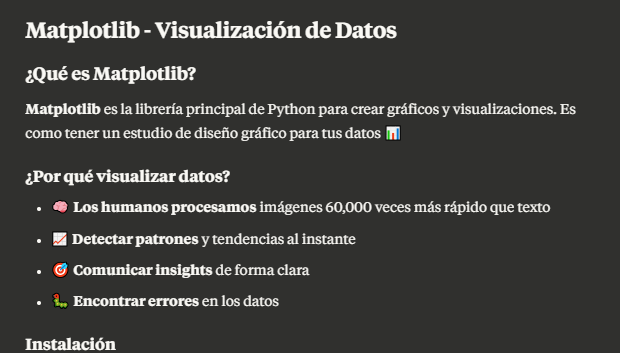

In [69]:

ticket_promedio = df["total"].mean()

print("Ticket promedio:", ticket_promedio)


Ticket promedio: 629.5


## 1. Conceptos Básicos

### 1.1 Tu primer gráfico

Matplotlib permite representar datos visualmente.

Un gráfico debería responder una pregunta, no simplemente “verse lindo”.

En el primer ejemplo observá cómo los valores de `x` y `y` se transforman en puntos unidos por una línea.


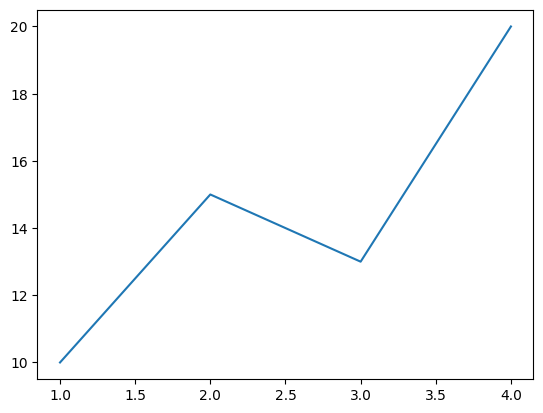

In [70]:
x = [1, 2, 3, 4]
y = [10, 15, 13, 20]

plt.plot(x, y)
plt.show()


## 1.2 Anatomía de un gráfico

Además de los datos podemos agregar:

- título;
- etiquetas de ejes;
- leyenda;
- grilla;
- otros elementos visuales.

La personalización debe ayudar a interpretar, no agregar ruido.


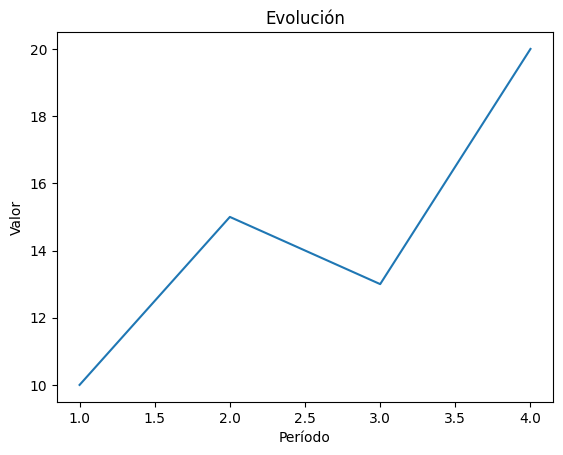

In [71]:
plt.plot(x, y)
plt.title("Evolución")
plt.xlabel("Período")
plt.ylabel("Valor")
plt.show()


## 2. Tipos de Gráficos Esenciales

### 2.1 Gráfico de Líneas - Tendencias en el tiempo

Las líneas son útiles cuando queremos observar evolución u orden temporal.

Antes de ejecutar, intentá imaginar la tendencia.


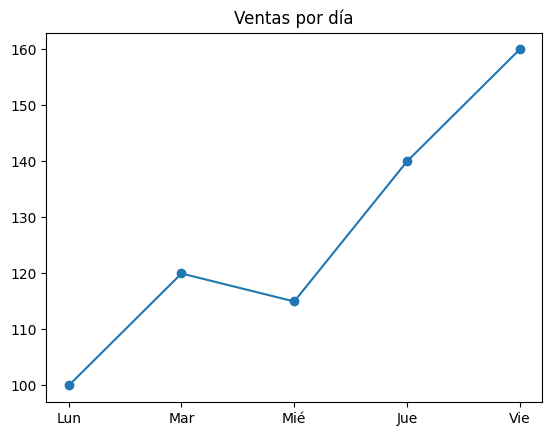

In [72]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie"]
ventas = [100, 120, 115, 140, 160]

plt.plot(dias, ventas, marker="o")
plt.title("Ventas por día")
plt.show()


## 2.2 Gráfico de Barras - Comparaciones

Las barras sirven para comparar magnitudes entre categorías.

Pregunta típica:

> ¿qué categoría tiene un valor mayor o menor?


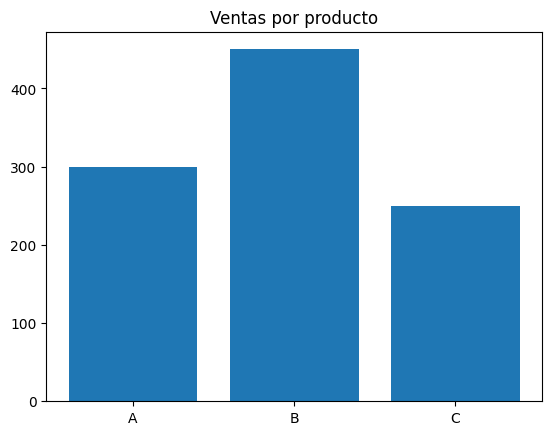

In [73]:
productos = ["A", "B", "C"]
ventas_producto = [300, 450, 250]

plt.bar(productos, ventas_producto)
plt.title("Ventas por producto")
plt.show()


## 2.3 Histograma - Distribuciones

Un histograma agrupa valores numéricos en intervalos y muestra cuántos datos caen en cada uno.

Sirve para observar:

- concentración;
- dispersión;
- forma de la distribución.

Probá después cambiar `bins`.


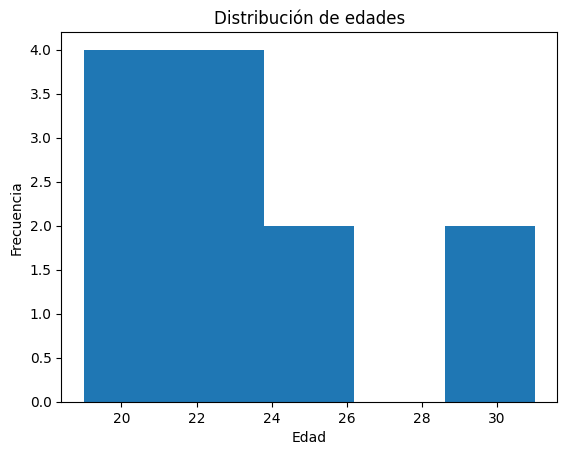

In [74]:
edades = [19, 20, 21, 21, 22, 23, 23, 23, 25, 26, 30, 31]

plt.hist(edades, bins=5)
plt.title("Distribución de edades")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.show()


## 2.4 Gráfico de Dispersión - Relaciones

Cada punto representa dos valores al mismo tiempo.

Es útil para explorar si dos variables parecen relacionarse.

Ver una tendencia visual **no demuestra causalidad**.


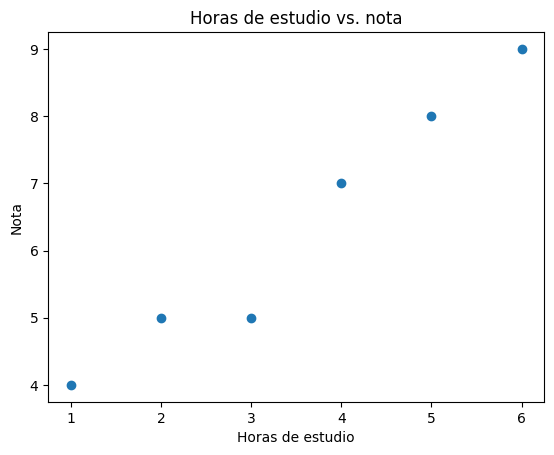

In [75]:
horas_estudio = [1, 2, 3, 4, 5, 6]
notas = [4, 5, 5, 7, 8, 9]

plt.scatter(horas_estudio, notas)
plt.xlabel("Horas de estudio")
plt.ylabel("Nota")
plt.title("Horas de estudio vs. nota")
plt.show()


## 3. Integración con Pandas - ¡El poder real!

### 3.1 Preparar datos con Pandas

Ahora conectamos ambos bloques:

1. Pandas prepara y resume los datos.
2. Matplotlib los representa visualmente.

Vamos a usar el `ventas.csv` que ya cargamos en la sección anterior.


In [76]:
resumen_categoria = (
    df.groupby("categoria", as_index=False)["total"]
      .sum()
)

resumen_categoria


,categoria,total
0,Accesorios,485
1,Electrónica,4510
2,Muebles,1300


## 3.2 Pandas + Matplotlib: El combo perfecto

Primero miramos la tabla resumida.

Después la graficamos.

Esto es importante: un gráfico depende del cálculo que hicimos antes.


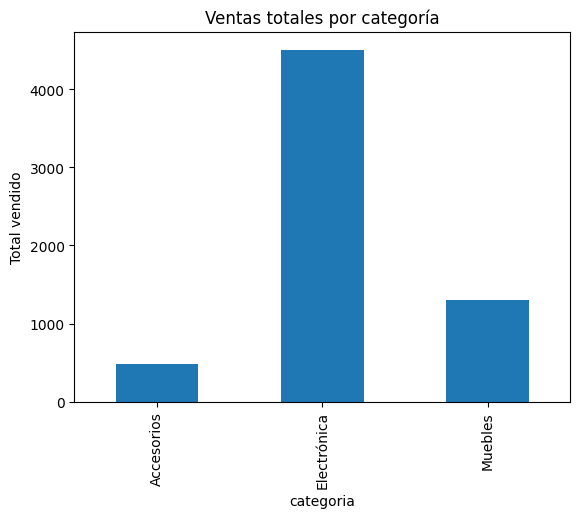

In [77]:
resumen_categoria.plot(
    x="categoria",
    y="total",
    kind="bar",
    legend=False,
    title="Ventas totales por categoría"
)

plt.ylabel("Total vendido")
plt.show()


## 3.3 Gráficos avanzados con Pandas

También podemos crear resúmenes con más de una métrica antes de graficar.

La clave sigue siendo la misma:

> pregunta → transformación → resumen → visualización


In [78]:
resumen_cliente = (
    df.groupby("cliente", as_index=False)
      .agg(
          total_vendido=("total", "sum"),
          cantidad_total=("cantidad", "sum")
      )
)

resumen_cliente


,cliente,total_vendido,cantidad_total
0,Cliente B,125,5
1,Cliente C,240,3
2,Cliente E,600,2
3,Cliente G,480,4
4,Cliente H,180,2
5,Cliente J,120,6
6,Empresa A,3000,2
7,Empresa D,400,1
8,Empresa F,700,1
9,Empresa I,450,3


## 4. Personalización y Estilo

### 4.1 Colores y estilos

Podemos ajustar tamaño, títulos, etiquetas y otros elementos.

La personalización debería mejorar la lectura del gráfico, no sobrecargarlo.


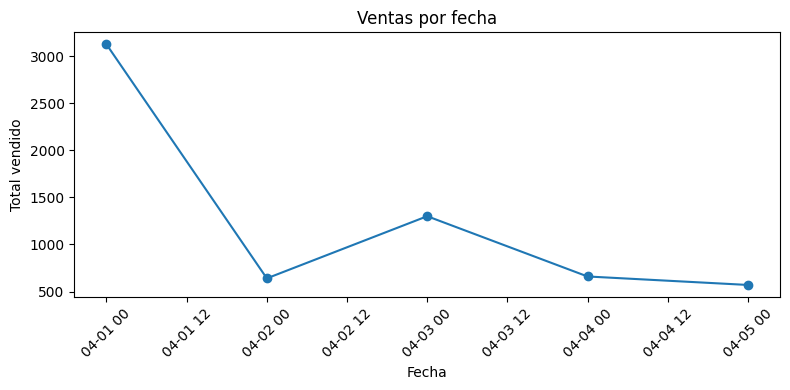

In [79]:
ventas_por_fecha = df.groupby("fecha")["total"].sum()

plt.figure(figsize=(8, 4))
plt.plot(ventas_por_fecha.index, ventas_por_fecha.values, marker="o")
plt.title("Ventas por fecha")
plt.xlabel("Fecha")
plt.ylabel("Total vendido")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Guardar Gráficos

Matplotlib también permite guardar una visualización como archivo.

Esto es útil para:

- informes;
- presentaciones;
- procesos automáticos;
- compartir resultados.


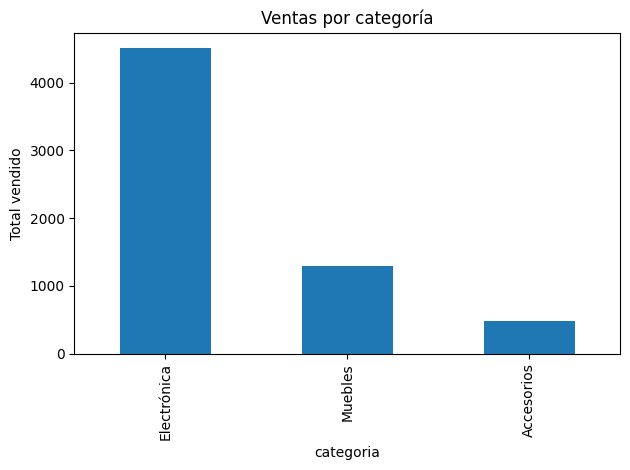

In [80]:
ventas_por_categoria.plot(kind="bar", title="Ventas por categoría")

plt.ylabel("Total vendido")
plt.tight_layout()
plt.savefig("ventas_por_categoria.png")
plt.show()


In [81]:
import os

print("¿Se creó el archivo?")
print(os.path.exists("ventas_por_categoria.png"))


¿Se creó el archivo?
True


## ✅ Cierre de la actividad

En este notebook recorriste el mismo orden conceptual de la clase:

1. manejo de errores;
2. bucles;
3. módulos e imports;
4. Pandas;
5. Matplotlib.

### Antes de terminar, intentá explicar con tus palabras:

- ¿para qué sirve `try/except`?
- ¿cuándo usarías `for` y cuándo `while`?
- ¿qué diferencia hay entre `break` y `continue`?
- ¿qué diferencia hay entre instalar e importar una librería?
- ¿qué hace `pd.read_csv()`?
- ¿cuándo usarías barras, líneas, histograma o dispersión?

La meta no es memorizar todas las instrucciones, sino entender **qué problema resuelve cada herramienta**.

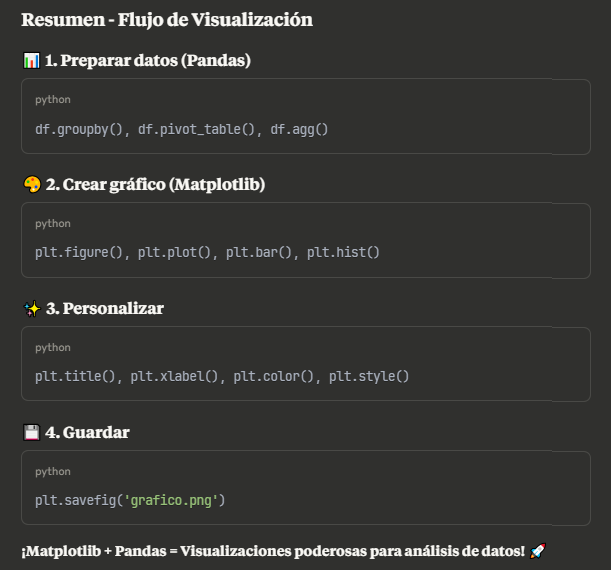
